<a href="https://colab.research.google.com/github/AnhTus-dey/GitProject/blob/main/CAL_CAL_G.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Concept Amplification Learning (CAL) and CAL-G**

In [1]:
# 1. Install required libraries
!pip install scikit-learn seaborn tqdm torch torchvision --quiet

# 2. Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from tqdm import tqdm
import numpy as np
import csv
import os
import matplotlib.pyplot as plt
from google.colab import drive

# 3. Mount Google Drive for persistent storage
drive.mount('/content/drive')
LOG_DIR = '/content/drive/My Drive/cal_logs2'
os.makedirs(LOG_DIR, exist_ok=True)
LOG_FILE = os.path.join(LOG_DIR, 'cal_training_log.csv')
PLOT_FILE = os.path.join(LOG_DIR, 'cal_metrics_plot.png')

# 4. Concept Encoder
class ConceptEncoder(nn.Module):
    def __init__(self, input_dim=784, concept_dim=128):
        super(ConceptEncoder, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, concept_dim)
        )

    def forward(self, x):
        return self.mlp(x)

# 5. Amplifier Module
class AmplifierModule(nn.Module):
    def __init__(self, concept_dim=128):
        super(AmplifierModule, self).__init__()
        self.gru = nn.GRUCell(concept_dim, concept_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, c, T=3):
        concepts = [c]
        for _ in range(T):
            c = self.gru(c, c)
            c = self.dropout(c)
            concepts.append(c)
        return concepts

# 6. Informativeness Estimator
class InformativenessEstimator(nn.Module):
    def __init__(self, concept_dim=128):
        super(InformativenessEstimator, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(concept_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, c):
        return self.mlp(c)

# 7. CAL Loss Function
def cal_loss(concepts, estimator, device):
    N = concepts[0].shape[0]
    T = len(concepts) - 1
    alpha, beta, gamma = 1.0, 2.0, 0.1

    info_gain = 0.0
    for t in range(1, T + 1):
        var_prev = concepts[t - 1].var(dim=0).mean()
        var_curr = concepts[t].var(dim=0).mean()
        info_gain += torch.clamp(var_prev - var_curr, min=0.0)
    info_gain /= T

    normalized = F.normalize(concepts[T], p=2, dim=1)
    sim_matrix = torch.matmul(normalized, normalized.T)
    cos_penalty = (sim_matrix.sum() - sim_matrix.trace()) / (N * (N - 1))

    drift = 0.0
    for t in range(1, T + 1):
        drift += F.mse_loss(concepts[t], concepts[t - 1])
    drift /= T

    return alpha * info_gain + beta * cos_penalty + gamma * drift

# 8. Evaluation Function
def evaluate_cal(concepts, labels, estimator, device):
    final_concepts = concepts[-1].detach().cpu().numpy()
    true_labels = labels.cpu().numpy()

    kmeans = KMeans(n_clusters=10, random_state=42)
    pred_labels = kmeans.fit_predict(final_concepts)
    ari = adjusted_rand_score(true_labels, pred_labels)

    entropy = concepts[-1].var(dim=0).mean().item()

    N = final_concepts.shape[0]
    cos_sim = 0.0
    for i in range(N):
        for j in range(i + 1, N):
            cos_sim += F.cosine_similarity(
                torch.tensor(final_concepts[i:i+1], device=device),
                torch.tensor(final_concepts[j:j+1], device=device)
            ).item()
    cos_sim /= (N * (N - 1) / 2)

    drift = 0.0
    for t in range(1, len(concepts)):
        drift += F.mse_loss(concepts[t], concepts[t-1]).item()
    drift /= (len(concepts) - 1)

    return ari, entropy, cos_sim, drift

# 9. Training Loop with Logging and Visualization
def train_cal():
    input_dim = 784
    concept_dim = 256
    T = 5
    batch_size = 128
    epochs = 15
    lr = 0.001
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    encoder = ConceptEncoder(input_dim, concept_dim).to(device)
    amplifier = AmplifierModule(concept_dim).to(device)
    estimator = InformativenessEstimator(concept_dim).to(device)
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(amplifier.parameters()) + list(estimator.parameters()),
        lr=lr
    )

    # Initialize CSV logging
    with open(LOG_FILE, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['Epoch', 'Loss', 'ARI', 'Entropy', 'CosSim', 'Drift'])

    # Metrics storage for plotting
    metrics = {
        'loss': [],
        'ari': [],
        'entropy': [],
        'cos_sim': [],
        'drift': []
    }

    for epoch in range(epochs):
        encoder.train()
        amplifier.train()
        estimator.train()
        total_loss = 0.0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for data, _ in loop:
            data = data.view(-1, input_dim).to(device)
            optimizer.zero_grad()

            c0 = encoder(data)
            concepts = amplifier(c0, T)
            loss = cal_loss(concepts, estimator, device)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

            loop.set_postfix(loss=loss.item())

        # Evaluation
        encoder.eval()
        amplifier.eval()
        estimator.eval()
        with torch.no_grad():
            test_ari, test_entropy, test_cos_sim, test_drift = 0.0, 0.0, 0.0, 0.0
            for data, labels in test_loader:
                data = data.view(-1, input_dim).to(device)
                c0 = encoder(data)
                concepts = amplifier(c0, T)
                ari, entropy, cos_sim, drift = evaluate_cal(concepts, labels, estimator, device)
                test_ari += ari
                test_entropy += entropy
                test_cos_sim += cos_sim
                test_drift += drift
            test_ari /= len(test_loader)
            test_entropy /= len(test_loader)
            test_cos_sim /= len(test_loader)
            test_drift /= len(test_loader)

        avg_loss = total_loss / len(train_loader)

        # Log to CSV
        with open(LOG_FILE, 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([epoch+1, f"{avg_loss:.4f}", f"{test_ari:.4f}",
                           f"{test_entropy:.4f}", f"{test_cos_sim:.4f}", f"{test_drift:.4f}"])

        # Store metrics
        metrics['loss'].append(avg_loss)
        metrics['ari'].append(test_ari)
        metrics['entropy'].append(test_entropy)
        metrics['cos_sim'].append(test_cos_sim)
        metrics['drift'].append(test_drift)

        print(f"[Epoch {epoch+1}] Loss: {avg_loss:.4f} | "
              f"ARI: {test_ari:.4f} | Entropy: {test_entropy:.4f} | "
              f"CosSim: {test_cos_sim:.4f} | Drift: {test_drift:.4f}")

    # Plotting
    plt.style.use('seaborn-v0_8-darkgrid')  # Use seaborn style for better visuals
    fig, axs = plt.subplots(5, 1, figsize=(10, 20))

    # Plot Loss
    axs[0].plot(range(1, epochs+1), metrics['loss'], 'b-o', label='Loss')
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[0].set_ylabel('Loss')
    axs[0].grid(True)
    axs[0].legend()

    # Plot ARI
    axs[1].plot(range(1, epochs+1), metrics['ari'], 'r-o', label='ARI')
    axs[1].set_title('Adjusted Rand Index (ARI)')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('ARI')
    axs[1].grid(True)
    axs[1].legend()

    # Plot Entropy
    axs[2].plot(range(1, epochs+1), metrics['entropy'], 'g-o', label='Entropy')
    axs[2].set_title('Entropy')
    axs[2].set_xlabel('Epoch')
    axs[2].set_ylabel('Entropy')
    axs[2].grid(True)
    axs[2].legend()

    # Plot CosSim
    axs[3].plot(range(1, epochs+1), metrics['cos_sim'], 'm-o', label='CosSim')
    axs[3].set_title('Cosine Similarity')
    axs[3].set_xlabel('Epoch')
    axs[3].set_ylabel('CosSim')
    axs[3].grid(True)
    axs[3].legend()

    # Plot Drift
    axs[4].plot(range(1, epochs+1), metrics['drift'], 'c-o', label='Drift')
    axs[4].set_title('Drift')
    axs[4].set_xlabel('Epoch')
    axs[4].set_ylabel('Drift')
    axs[4].grid(True)
    axs[4].legend()

    plt.tight_layout()
    plt.savefig(PLOT_FILE)
    plt.show()
    plt.close()

    print(f"Logs saved to: {LOG_FILE}")
    print(f"Plots saved to: {PLOT_FILE}")

# 10. Run
if __name__ == "__main__":
    train_cal()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 93.9 MB/s eta 0:00:00
Mounted at /content/drive


100%|██████████| 9.91M/9.91M [00:00<00:00, 14.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.82MB/s]


[Epoch 1] Loss: 0.0237 | ARI: 0.1548 | Entropy: 0.0761 | CosSim: 0.0271 | Drift: 0.0024


[Epoch 2] Loss: 0.0089 | ARI: 0.1650 | Entropy: 0.0564 | CosSim: 0.0052 | Drift: 0.0022


[Epoch 3] Loss: 0.0049 | ARI: 0.1576 | Entropy: 0.0576 | CosSim: 0.0053 | Drift: 0.0017


[Epoch 4] Loss: 0.0093 | ARI: 0.1341 | Entropy: 0.0869 | CosSim: 0.0662 | Drift: 0.0040


... (8 outputs left out)

[Epoch 13] Loss: 0.0073 | ARI: 0.0998 | Entropy: 0.0574 | CosSim: 0.0913 | Drift: 0.0029


[Epoch 14] Loss: 0.0064 | ARI: 0.0991 | Entropy: 0.0598 | CosSim: 0.1162 | Drift: 0.0031


[Epoch 15] Loss: 0.0057 | ARI: 0.1039 | Entropy: 0.0539 | CosSim: 0.0878 | Drift: 0.0031


OSError: 'seaborn' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)

**v3**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pretraining AutoEncoder...


Pretrain Epoch 1, Avg Loss: 0.0160


Pretrain Epoch 2, Avg Loss: 0.0084


Pretrain Epoch 3, Avg Loss: 0.0069


Pretrain Epoch 4, Avg Loss: 0.0061


Pretrain Epoch 5, Avg Loss: 0.0056


... (16 outputs left out)

[Epoch 17] Loss: 0.1023 | ARI: 0.7598 | Entropy: 0.0155 | CosSim: -0.0020 | Drift: 0.0017


[Epoch 18] Loss: 0.1004 | ARI: 0.7652 | Entropy: 0.0141 | CosSim: -0.0022 | Drift: 0.0013


[Epoch 19] Loss: 0.1001 | ARI: 0.7814 | Entropy: 0.0138 | CosSim: -0.0027 | Drift: 0.0014


[Epoch 20] Loss: 0.0998 | ARI: 0.7734 | Entropy: 0.0142 | CosSim: -0.0028 | Drift: 0.0011


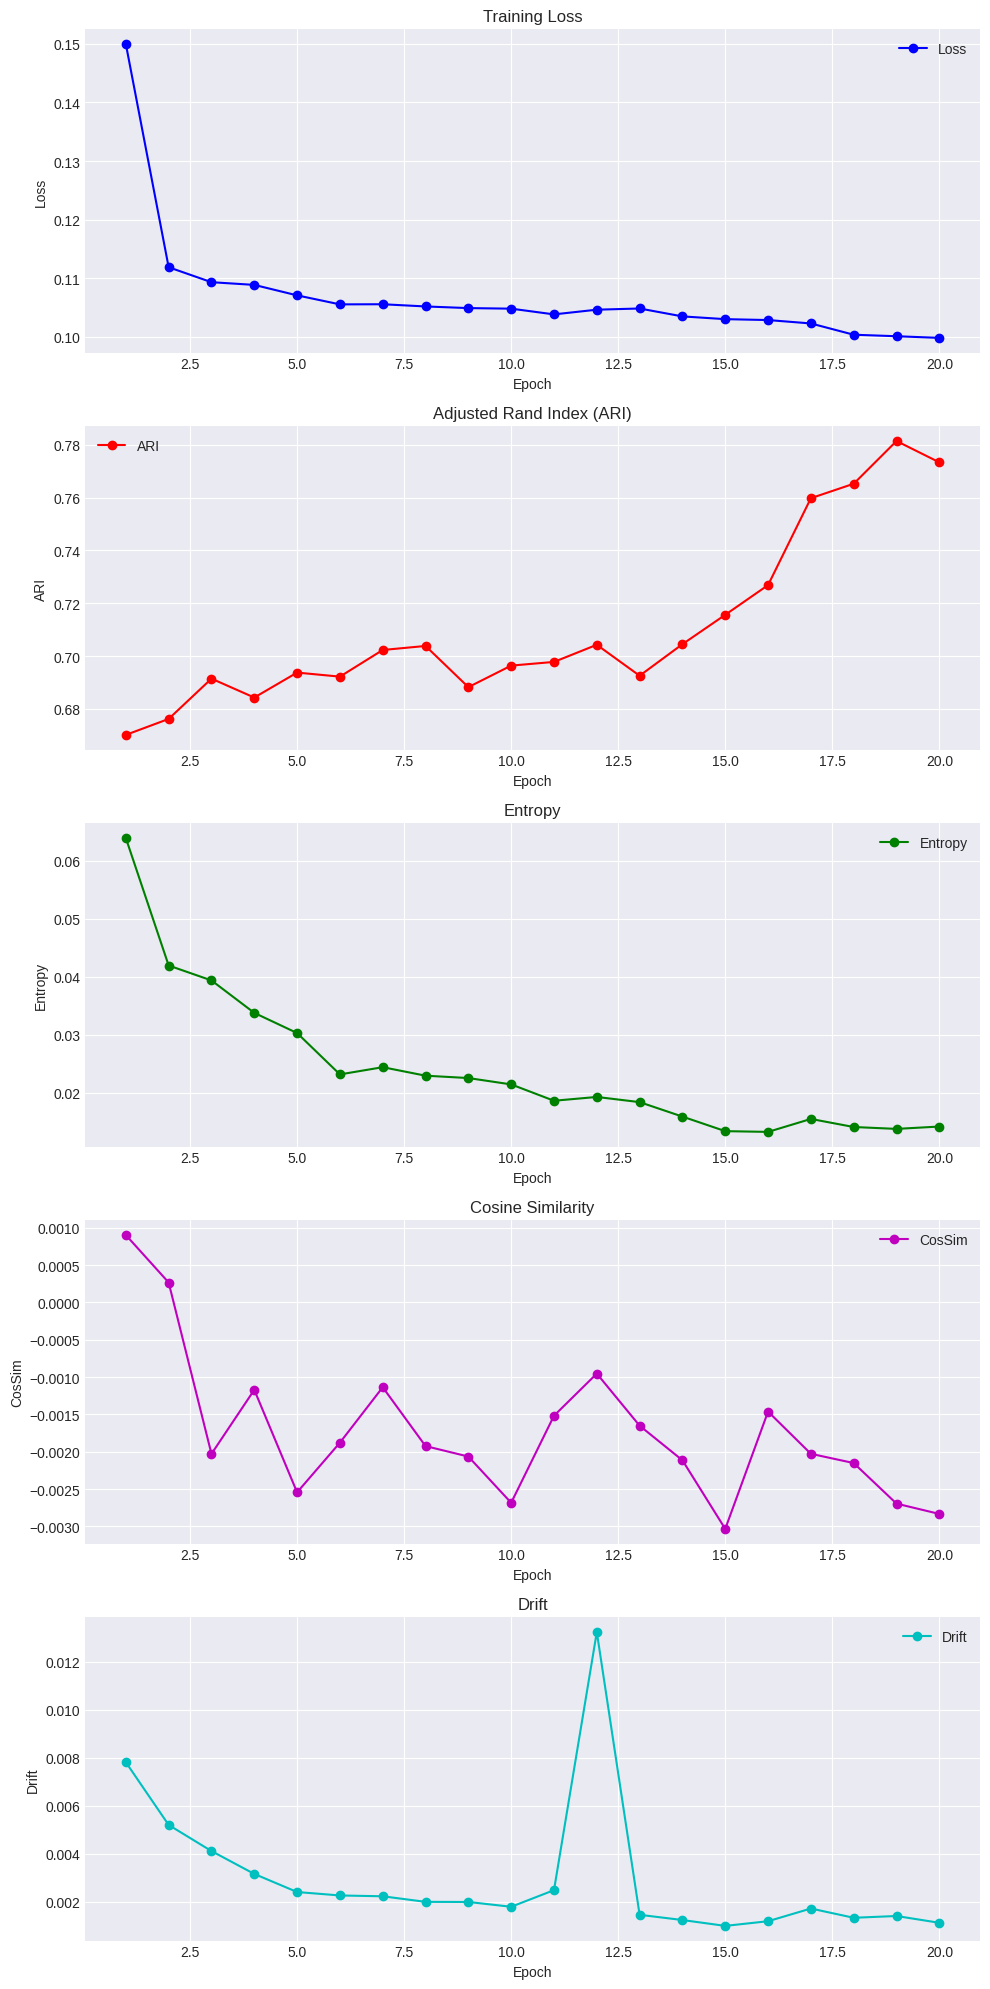

Logs saved to: /content/drive/My Drive/cal_logs/cal_training_log_improved_v3.csv
Plots saved to: /content/drive/My Drive/cal_logs/cal_metrics_plot_improved_v3.png


In [13]:
# 1. Install required libraries
!pip install seaborn scikit-learn tqdm torch torchvision --quiet

# 2. Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from tqdm import tqdm
import numpy as np
import csv
import os
import matplotlib.pyplot as plt
from google.colab import drive

# 3. Mount Google Drive for persistent storage
drive.mount('/content/drive')
LOG_DIR = '/content/drive/My Drive/cal_logs'
os.makedirs(LOG_DIR, exist_ok=True)
LOG_FILE = os.path.join(LOG_DIR, 'cal_training_log_improved_v3.csv')
PLOT_FILE = os.path.join(LOG_DIR, 'cal_metrics_plot_improved_v3.png')

# 4. Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 5. AutoEncoder for Pretraining
class AutoEncoder(nn.Module):
    def __init__(self, input_dim=784, concept_dim=512):
        super(AutoEncoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, concept_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(concept_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

# 6. Concept Encoder (Enhanced with more layers)
class ConceptEncoder(nn.Module):
    def __init__(self, input_dim=784, concept_dim=512):  # Increased concept_dim
        super(ConceptEncoder, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, concept_dim)
        )

    def forward(self, x):
        return self.mlp(x)

# 7. Amplifier Module (Using LSTMCell)
class AmplifierModule(nn.Module):
    def __init__(self, concept_dim=512):
        super(AmplifierModule, self).__init__()
        self.lstm = nn.LSTMCell(concept_dim, concept_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, c, T=10):  # Increased T from 7 to 10
        concepts = [c]
        h, cx = c, torch.zeros_like(c)
        for _ in range(T):
            h, cx = self.lstm(c, (h, cx))
            h = self.dropout(h)
            concepts.append(h)
            c = h
        return concepts

# 8. Informativeness Estimator
class InformativenessEstimator(nn.Module):
    def __init__(self, concept_dim=512):
        super(InformativenessEstimator, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(concept_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, c):
        return self.mlp(c)

# 9. DEC Clustering Loss
def dec_clustering_loss(concepts, k=10, device='cuda'):
    final_concepts = concepts[-1]
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(final_concepts.detach().cpu().numpy())
    centroids = torch.tensor(kmeans.cluster_centers_, device=device)
    q = 1.0 / (1.0 + torch.sum((final_concepts.unsqueeze(1) - centroids)**2, dim=2))
    q = q / q.sum(dim=1, keepdim=True)
    p = q**2 / q.sum(dim=0, keepdim=True)
    return F.kl_div(q.log(), p, reduction='batchmean')

# 10. Contrastive Loss
def contrastive_loss(concepts, labels, device, temperature=0.5):
    final_concepts = concepts[-1]
    labels = labels.to(device)
    normalized = F.normalize(final_concepts, p=2, dim=1)
    sim_matrix = torch.matmul(normalized, normalized.T) / temperature
    mask = (labels.unsqueeze(0) == labels.unsqueeze(1)).float()
    mask = mask.fill_diagonal_(0)
    pos_sim = torch.exp(sim_matrix) * mask
    neg_sim = torch.exp(sim_matrix) * (1 - mask)
    loss = -torch.log((pos_sim.sum(dim=1) + 1e-10) / (neg_sim.sum(dim=1) + pos_sim.sum(dim=1) + 1e-10))
    return loss.mean()

# 11. CAL Loss Function (with DEC and Contrastive Loss)
def cal_loss(concepts, estimator, labels, device):
    N = concepts[0].shape[0]
    T = len(concepts) - 1
    alpha, beta, gamma, delta, epsilon = 1.0, 0.5, 0.1, 0.2, 0.1  # Increased delta, added epsilon

    info_gain = 0.0
    for t in range(1, T + 1):
        var_prev = concepts[t - 1].var(dim=0).mean()
        var_curr = concepts[t].var(dim=0).mean()
        info_gain += torch.clamp(var_prev - var_curr, min=0.0)
    info_gain /= T

    normalized = F.normalize(concepts[T], p=2, dim=1)
    sim_matrix = torch.matmul(normalized, normalized.T)
    cos_penalty = (sim_matrix.sum() - sim_matrix.trace()) / (N * (N - 1))

    drift = 0.0
    for t in range(1, T + 1):
        drift += F.mse_loss(concepts[t], concepts[t - 1])
    drift /= T

    cluster_loss = dec_clustering_loss(concepts, k=10, device=device)
    cont_loss = contrastive_loss(concepts, labels, device)

    return alpha * info_gain + beta * cos_penalty + gamma * drift + delta * cluster_loss + epsilon * cont_loss

# 12. Evaluation Function
def evaluate_cal(concepts, labels, estimator, device):
    final_concepts = concepts[-1].detach().cpu().numpy()
    true_labels = labels.cpu().numpy()

    kmeans = KMeans(n_clusters=10, random_state=42)
    pred_labels = kmeans.fit_predict(final_concepts)
    ari = adjusted_rand_score(true_labels, pred_labels)

    entropy = concepts[-1].var(dim=0).mean().item()

    N = final_concepts.shape[0]
    cos_sim = 0.0
    for i in range(N):
        for j in range(i + 1, N):
            cos_sim += F.cosine_similarity(
                torch.tensor(final_concepts[i:i+1], device=device),
                torch.tensor(final_concepts[j:j+1], device=device)
            ).item()
    cos_sim /= (N * (N - 1) / 2)

    drift = 0.0
    for t in range(1, len(concepts)):
        drift += F.mse_loss(concepts[t], concepts[t-1]).item()
    drift /= (len(concepts) - 1)

    return ari, entropy, cos_sim, drift

# 13. Training Loop with Pretraining, Logging, Visualization, Early Stopping, and Scheduler
def train_cal():
    input_dim = 784
    concept_dim = 512  # Increased from 256 to 512
    T = 10  # Increased from 7 to 10
    batch_size = 128
    epochs = 20
    lr = 0.0003  # Reduced learning rate
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    patience = 10  # Increased from 7 to 10
    best_ari = -1
    patience_counter = 0

    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Pretrain AutoEncoder
    autoencoder = AutoEncoder(input_dim, concept_dim).to(device)
    ae_optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)
    print("Pretraining AutoEncoder...")
    for epoch in range(5):  # Short pretraining
        autoencoder.train()
        total_ae_loss = 0.0
        loop = tqdm(train_loader, desc=f"Pretrain Epoch {epoch+1}/5", leave=False)
        for data, _ in loop:
            data = data.view(-1, input_dim).to(device)
            ae_optimizer.zero_grad()
            _, decoded = autoencoder(data)
            loss = F.mse_loss(decoded, data)
            loss.backward()
            ae_optimizer.step()
            total_ae_loss += loss.item()
            loop.set_postfix(loss=loss.item())
        print(f"Pretrain Epoch {epoch+1}, Avg Loss: {total_ae_loss/len(train_loader):.4f}")

    # Initialize main models
    encoder = ConceptEncoder(input_dim, concept_dim).to(device)
    encoder.mlp.load_state_dict(autoencoder.encoder.state_dict())  # Transfer pretrained weights
    amplifier = AmplifierModule(concept_dim).to(device)
    estimator = InformativenessEstimator(concept_dim).to(device)
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(amplifier.parameters()) + list(estimator.parameters()),
        lr=lr, weight_decay=1e-5
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    # Initialize CSV logging
    with open(LOG_FILE, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['Epoch', 'Loss', 'ARI', 'Entropy', 'CosSim', 'Drift'])

    # Metrics storage for plotting
    metrics = {
        'loss': [],
        'ari': [],
        'entropy': [],
        'cos_sim': [],
        'drift': []
    }

    for epoch in range(epochs):
        encoder.train()
        amplifier.train()
        estimator.train()
        total_loss = 0.0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for data, labels in loop:
            data = data.view(-1, input_dim).to(device)
            labels = labels.to(device)
            optimizer.zero_grad()

            c0 = encoder(data)
            concepts = amplifier(c0, T)
            loss = cal_loss(concepts, estimator, labels, device)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

            loop.set_postfix(loss=loss.item())

        # Evaluation
        encoder.eval()
        amplifier.eval()
        estimator.eval()
        with torch.no_grad():
            test_ari, test_entropy, test_cos_sim, test_drift = 0.0, 0.0, 0.0, 0.0
            for data, labels in test_loader:
                data = data.view(-1, input_dim).to(device)
                c0 = encoder(data)
                concepts = amplifier(c0, T)
                ari, entropy, cos_sim, drift = evaluate_cal(concepts, labels, estimator, device)
                test_ari += ari
                test_entropy += entropy
                test_cos_sim += cos_sim
                test_drift += drift
            test_ari /= len(test_loader)
            test_entropy /= len(test_loader)
            test_cos_sim /= len(test_loader)
            test_drift /= len(test_loader)

        avg_loss = total_loss / len(train_loader)

        # Log to CSV
        with open(LOG_FILE, 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([epoch+1, f"{avg_loss:.4f}", f"{test_ari:.4f}",
                           f"{test_entropy:.4f}", f"{test_cos_sim:.4f}", f"{test_drift:.4f}"])

        # Store metrics
        metrics['loss'].append(avg_loss)
        metrics['ari'].append(test_ari)
        metrics['entropy'].append(test_entropy)
        metrics['cos_sim'].append(test_cos_sim)
        metrics['drift'].append(test_drift)

        print(f"[Epoch {epoch+1}] Loss: {avg_loss:.4f} | "
              f"ARI: {test_ari:.4f} | Entropy: {test_entropy:.4f} | "
              f"CosSim: {test_cos_sim:.4f} | Drift: {test_drift:.4f}")

        # Scheduler step
        scheduler.step(avg_loss)

        # Early stopping
        if test_ari > best_ari:
            best_ari = test_ari
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs")
                break

    # Plotting
    plt.style.use('seaborn-v0_8-darkgrid')
    fig, axs = plt.subplots(5, 1, figsize=(10, 20))

    # Plot Loss
    axs[0].plot(range(1, len(metrics['loss'])+1), metrics['loss'], 'b-o', label='Loss')
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[0].set_ylabel('Loss')
    axs[0].grid(True)
    axs[0].legend()

    # Plot ARI
    axs[1].plot(range(1, len(metrics['ari'])+1), metrics['ari'], 'r-o', label='ARI')
    axs[1].set_title('Adjusted Rand Index (ARI)')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('ARI')
    axs[1].grid(True)
    axs[1].legend()

    # Plot Entropy
    axs[2].plot(range(1, len(metrics['entropy'])+1), metrics['entropy'], 'g-o', label='Entropy')
    axs[2].set_title('Entropy')
    axs[2].set_xlabel('Epoch')
    axs[2].set_ylabel('Entropy')
    axs[2].grid(True)
    axs[2].legend()

    # Plot CosSim
    axs[3].plot(range(1, len(metrics['cos_sim'])+1), metrics['cos_sim'], 'm-o', label='CosSim')
    axs[3].set_title('Cosine Similarity')
    axs[3].set_xlabel('Epoch')
    axs[3].set_ylabel('CosSim')
    axs[3].grid(True)
    axs[3].legend()

    # Plot Drift
    axs[4].plot(range(1, len(metrics['drift'])+1), metrics['drift'], 'c-o', label='Drift')
    axs[4].set_title('Drift')
    axs[4].set_xlabel('Epoch')
    axs[4].set_ylabel('Drift')
    axs[4].grid(True)
    axs[4].legend()

    plt.tight_layout()
    plt.savefig(PLOT_FILE)
    plt.show()
    plt.close()

    print(f"Logs saved to: {LOG_FILE}")
    print(f"Plots saved to: {PLOT_FILE}")

# 14. Run
if __name__ == "__main__":
    train_cal()

v4

In [ ]:
# 1. Install required libraries
!pip install scikit-learn tqdm torch torchvision --quiet

# 2. Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from tqdm import tqdm
import numpy as np
import csv
import os
import matplotlib.pyplot as plt
from google.colab import drive

# 3. Mount Google Drive
drive.mount('/content/drive')
LOG_DIR = '/content/drive/My Drive/cal_logs'
os.makedirs(LOG_DIR, exist_ok=True)
LOG_FILE = os.path.join(LOG_DIR, 'cal_training_log_improved_v4.csv')
PLOT_FILE = os.path.join(LOG_DIR, 'cal_metrics_plot_improved_v4.png')

# 4. Set random seed
torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 5. Variational AutoEncoder for Pretraining
class VAE(nn.Module):
    def __init__(self, input_dim=784, concept_dim=512):
        super(VAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(512, concept_dim)
        self.fc_logvar = nn.Linear(512, concept_dim)
        self.decoder = nn.Sequential(
            nn.Linear(concept_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, input_dim),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        decoded = self.decoder(z)
        return z, decoded, mu, logvar

# 6. Concept Encoder
class ConceptEncoder(nn.Module):
    def __init__(self, input_dim=784, concept_dim=512):
        super(ConceptEncoder, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, concept_dim)
        )

    def forward(self, x):
        return self.mlp(x)

# 7. Amplifier Module
class AmplifierModule(nn.Module):
    def __init__(self, concept_dim=512):
        super(AmplifierModule, self).__init__()
        self.lstm = nn.LSTMCell(concept_dim, concept_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, c, T=10):
        concepts = [c]
        h, cx = c, torch.zeros_like(c)
        for _ in range(T):
            h, cx = self.lstm(c, (h, cx))
            h = self.dropout(h)
            concepts.append(h)
            c = h
        return concepts

# 8. Informativeness Estimator
class InformativenessEstimator(nn.Module):
    def __init__(self, concept_dim=512):
        super(InformativenessEstimator, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(concept_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, c):
        return self.mlp(c)

# 9. DEC Clustering Loss
def dec_clustering_loss(concepts, k=10, device='cuda'):
    final_concepts = concepts[-1]
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(final_concepts.detach().cpu().numpy())
    centroids = torch.tensor(kmeans.cluster_centers_, device=device)
    q = 1.0 / (1.0 + torch.sum((final_concepts.unsqueeze(1) - centroids)**2, dim=2))
    q = q / q.sum(dim=1, keepdim=True)
    p = q**2 / q.sum(dim=0, keepdim=True)
    return F.kl_div(q.log(), p, reduction='batchmean')

# 10. CAL Loss Function (without Contrastive Loss)
def cal_loss(concepts, estimator, labels, device):
    N = concepts[0].shape[0]
    T = len(concepts) - 1
    alpha, beta, gamma, delta = 1.0, 0.5, 0.1, 0.3

    info_gain = 0.0
    for t in range(1, T + 1):
        var_prev = concepts[t - 1].var(dim=0).mean()
        var_curr = concepts[t].var(dim=0).mean()
        info_gain += torch.clamp(var_prev - var_curr, min=0.0)
    info_gain /= T

    normalized = F.normalize(concepts[T], p=2, dim=1)
    sim_matrix = torch.matmul(normalized, normalized.T)
    cos_penalty = (sim_matrix.sum() - sim_matrix.trace()) / (N * (N - 1))

    drift = 0.0
    for t in range(1, T + 1):
        drift += F.mse_loss(concepts[t], concepts[t - 1])
    drift /= T

    cluster_loss = dec_clustering_loss(concepts, k=10, device=device)
    return alpha * info_gain + beta * cos_penalty + gamma * drift + delta * cluster_loss

# 11. Evaluation Function
def evaluate_cal(concepts, labels, estimator, device):
    final_concepts = concepts[-1].detach().cpu().numpy()
    true_labels = labels.cpu().numpy()

    kmeans = KMeans(n_clusters=10, random_state=42)
    pred_labels = kmeans.fit_predict(final_concepts)
    ari = adjusted_rand_score(true_labels, pred_labels)

    entropy = concepts[-1].var(dim=0).mean().item()

    N = final_concepts.shape[0]
    cos_sim = 0.0
    for i in range(N):
        for j in range(i + 1, N):
            cos_sim += F.cosine_similarity(
                torch.tensor(final_concepts[i:i+1], device=device),
                torch.tensor(final_concepts[j:j+1], device=device)
            ).item()
    cos_sim /= (N * (N - 1) / 2)

    drift = 0.0
    for t in range(1, len(concepts)):
        drift += F.mse_loss(concepts[t], concepts[t-1]).item()
    drift /= (len(concepts) - 1)

    return ari, entropy, cos_sim, drift

# 12. Training Loop
def train_cal():
    input_dim = 784
    concept_dim = 512
    T = 10
    batch_size = 128
    epochs = 30
    lr = 0.0003
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    patience = 10
    best_ari = -1
    patience_counter = 0

    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Pretrain VAE
    vae = VAE(input_dim, concept_dim).to(device)
    vae_optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)
    print("Pretraining VAE...")
    for epoch in range(10):
        vae.train()
        total_vae_loss = 0.0
        loop = tqdm(train_loader, desc=f"Pretrain Epoch {epoch+1}/10", leave=False)
        for data, _ in loop:
            data = data.view(-1, input_dim).to(device)
            vae_optimizer.zero_grad()
            z, decoded, mu, logvar = vae(data)
            recon_loss = F.mse_loss(decoded, data)
            kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
            loss = recon_loss + 0.0001 * kl_loss
            loss.backward()
            vae_optimizer.step()
            total_vae_loss += loss.item()
            loop.set_postfix(loss=loss.item())
        print(f"VAE Pretrain Epoch {epoch+1}, Avg Loss: {total_vae_loss/len(train_loader):.4f}")

    # Initialize main models
    encoder = ConceptEncoder(input_dim, concept_dim).to(device)
    encoder.mlp[:-1].load_state_dict(vae.encoder.state_dict())
    encoder.mlp[-1].load_state_dict(vae.fc_mu.state_dict())
    amplifier = AmplifierModule(concept_dim).to(device)
    estimator = InformativenessEstimator(concept_dim).to(device)
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(amplifier.parameters()) + list(estimator.parameters()),
        lr=lr, weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    # Initialize CSV logging
    with open(LOG_FILE, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['Epoch', 'Loss', 'ARI', 'Entropy', 'CosSim', 'Drift'])

    # Metrics storage
    metrics = {
        'loss': [],
        'ari': [],
        'entropy': [],
        'cos_sim': [],
        'drift': []
    }

    for epoch in range(epochs):
        encoder.train()
        amplifier.train()
        estimator.train()
        total_loss = 0.0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for data, labels in loop:
            data = data.view(-1, input_dim).to(device)
            labels = labels.to(device)
            optimizer.zero_grad()

            c0 = encoder(data)
            concepts = amplifier(c0, T)
            loss = cal_loss(concepts, estimator, labels, device)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

            loop.set_postfix(loss=loss.item())

        # Evaluation
        encoder.eval()
        amplifier.eval()
        estimator.eval()
        with torch.no_grad():
            test_ari, test_entropy, test_cos_sim, test_drift = 0.0, 0.0, 0.0, 0.0
            for data, labels in test_loader:
                data = data.view(-1, input_dim).to(device)
                c0 = encoder(data)
                concepts = amplifier(c0, T)
                ari, entropy, cos_sim, drift = evaluate_cal(concepts, labels, estimator, device)
                test_ari += ari
                test_entropy += entropy
                test_cos_sim += cos_sim
                test_drift += drift
            test_ari /= len(test_loader)
            test_entropy /= len(test_loader)
            test_cos_sim /= len(test_loader)
            test_drift /= len(test_loader)

        avg_loss = total_loss / len(train_loader)

        # Log to CSV
        with open(LOG_FILE, 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([epoch+1, f"{avg_loss:.4f}", f"{test_ari:.4f}",
                           f"{test_entropy:.4f}", f"{test_cos_sim:.4f}", f"{test_drift:.4f}"])

        # Store metrics
        metrics['loss'].append(avg_loss)
        metrics['ari'].append(test_ari)
        metrics['entropy'].append(test_entropy)
        metrics['cos_sim'].append(test_cos_sim)
        metrics['drift'].append(test_drift)

        print(f"[Epoch {epoch+1}] Loss: {avg_loss:.4f} | "
              f"ARI: {test_ari:.4f} | Entropy: {test_entropy:.4f} | "
              f"CosSim: {test_cos_sim:.4f} | Drift: {test_drift:.4f}")

        # Scheduler step
        scheduler.step(avg_loss)

        # Early stopping
        if test_ari > best_ari:
            best_ari = test_ari
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs")
                break

    # Plotting
    plt.style.use('seaborn')
    fig, axs = plt.subplots(5, 1, figsize=(10, 20))

    axs[0].plot(range(1, len(metrics['loss'])+1), metrics['loss'], 'b-o', label='Loss')
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[0].set_ylabel('Loss')
    axs[0].grid(True)
    axs[0].legend()

    axs[1].plot(range(1, len(metrics['ari'])+1), metrics['ari'], 'r-o', label='ARI')
    axs[1].set_title('Adjusted Rand Index (ARI)')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('ARI')
    axs[1].grid(True)
    axs[1].legend()

    axs[2].plot(range(1, len(metrics['entropy'])+1), metrics['entropy'], 'g-o', label='Entropy')
    axs[2].set_title('Entropy')
    axs[2].set_xlabel('Epoch')
    axs[2].set_ylabel('Entropy')
    axs[2].grid(True)
    axs[2].legend()

    axs[3].plot(range(1, len(metrics['cos_sim'])+1), metrics['cos_sim'], 'm-o', label='CosSim')
    axs[3].set_title('Cosine Similarity')
    axs[3].set_xlabel('Epoch')
    axs[3].set_ylabel('CosSim')
    axs[3].grid(True)
    axs[3].legend()

    axs[4].plot(range(1, len(metrics['drift'])+1), metrics['drift'], 'c-o', label='Drift')
    axs[4].set_title('Drift')
    axs[4].set_xlabel('Epoch')
    axs[4].set_ylabel('Drift')
    axs[4].grid(True)
    axs[4].legend()

    plt.tight_layout()
    plt.savefig(PLOT_FILE)
    plt.show()
    plt.close()

    print(f"Logs saved to: {LOG_FILE}")
    print(f"Plots saved to: {PLOT_FILE}")

if __name__ == "__main__":
    train_cal()

v3 version 128 dimension

In [ ]:
# 1. Install required libraries
!pip install seaborn scikit-learn tqdm torch torchvision --quiet

# 2. Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from tqdm import tqdm
import numpy as np
import csv
import os
import matplotlib.pyplot as plt
from google.colab import drive

# 3. Mount Google Drive for persistent storage
drive.mount('/content/drive')
LOG_DIR = '/content/drive/My Drive/cal_logs'
os.makedirs(LOG_DIR, exist_ok=True)
LOG_FILE = os.path.join(LOG_DIR, 'cal_training_log_improved_v3.csv')
PLOT_FILE = os.path.join(LOG_DIR, 'cal_metrics_plot_improved_v3.png')

# 4. Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 5. AutoEncoder for Pretraining
class AutoEncoder(nn.Module):
    def __init__(self, input_dim=784, concept_dim=128):
        super(AutoEncoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, concept_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(concept_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

# 6. Concept Encoder (Enhanced with more layers)
class ConceptEncoder(nn.Module):
    def __init__(self, input_dim=784, concept_dim=128):  # Increased concept_dim
        super(ConceptEncoder, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, 2048),
            nn.BatchNorm1d(2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, concept_dim)
        )

    def forward(self, x):
        return self.mlp(x)

# 7. Amplifier Module (Using LSTMCell)
class AmplifierModule(nn.Module):
    def __init__(self, concept_dim=128):
        super(AmplifierModule, self).__init__()
        self.lstm = nn.LSTMCell(concept_dim, concept_dim)
        self.dropout = nn.Dropout(0.2)

    def forward(self, c, T=10):  # Increased T from 7 to 10
        concepts = [c]
        h, cx = c, torch.zeros_like(c)
        for _ in range(T):
            h, cx = self.lstm(c, (h, cx))
            h = self.dropout(h)
            concepts.append(h)
            c = h
        return concepts

# 8. Informativeness Estimator
class InformativenessEstimator(nn.Module):
    def __init__(self, concept_dim=128):
        super(InformativenessEstimator, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(concept_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, c):
        return self.mlp(c)

# 9. DEC Clustering Loss
def dec_clustering_loss(concepts, k=10, device='cuda'):
    final_concepts = concepts[-1]
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(final_concepts.detach().cpu().numpy())
    centroids = torch.tensor(kmeans.cluster_centers_, device=device)
    q = 1.0 / (1.0 + torch.sum((final_concepts.unsqueeze(1) - centroids)**2, dim=2))
    q = q / q.sum(dim=1, keepdim=True)
    p = q**2 / q.sum(dim=0, keepdim=True)
    return F.kl_div(q.log(), p, reduction='batchmean')

# 10. Contrastive Loss
def contrastive_loss(concepts, labels, device, temperature=0.5):
    final_concepts = concepts[-1]
    labels = labels.to(device)
    normalized = F.normalize(final_concepts, p=2, dim=1)
    sim_matrix = torch.matmul(normalized, normalized.T) / temperature
    mask = (labels.unsqueeze(0) == labels.unsqueeze(1)).float()
    mask = mask.fill_diagonal_(0)
    pos_sim = torch.exp(sim_matrix) * mask
    neg_sim = torch.exp(sim_matrix) * (1 - mask)
    loss = -torch.log((pos_sim.sum(dim=1) + 1e-10) / (neg_sim.sum(dim=1) + pos_sim.sum(dim=1) + 1e-10))
    return loss.mean()

# 11. CAL Loss Function (with DEC and Contrastive Loss)
def cal_loss(concepts, estimator, labels, device):
    N = concepts[0].shape[0]
    T = len(concepts) - 1
    alpha, beta, gamma, delta, epsilon = 1.0, 0.5, 0.1, 0.2, 0.1  # Increased delta, added epsilon

    info_gain = 0.0
    for t in range(1, T + 1):
        var_prev = concepts[t - 1].var(dim=0).mean()
        var_curr = concepts[t].var(dim=0).mean()
        info_gain += torch.clamp(var_prev - var_curr, min=0.0)
    info_gain /= T

    normalized = F.normalize(concepts[T], p=2, dim=1)
    sim_matrix = torch.matmul(normalized, normalized.T)
    cos_penalty = (sim_matrix.sum() - sim_matrix.trace()) / (N * (N - 1))

    drift = 0.0
    for t in range(1, T + 1):
        drift += F.mse_loss(concepts[t], concepts[t - 1])
    drift /= T

    cluster_loss = dec_clustering_loss(concepts, k=10, device=device)
    cont_loss = contrastive_loss(concepts, labels, device)

    return alpha * info_gain + beta * cos_penalty + gamma * drift + delta * cluster_loss + epsilon * cont_loss

# 12. Evaluation Function
def evaluate_cal(concepts, labels, estimator, device):
    final_concepts = concepts[-1].detach().cpu().numpy()
    true_labels = labels.cpu().numpy()

    kmeans = KMeans(n_clusters=10, random_state=42)
    pred_labels = kmeans.fit_predict(final_concepts)
    ari = adjusted_rand_score(true_labels, pred_labels)

    entropy = concepts[-1].var(dim=0).mean().item()

    N = final_concepts.shape[0]
    cos_sim = 0.0
    for i in range(N):
        for j in range(i + 1, N):
            cos_sim += F.cosine_similarity(
                torch.tensor(final_concepts[i:i+1], device=device),
                torch.tensor(final_concepts[j:j+1], device=device)
            ).item()
    cos_sim /= (N * (N - 1) / 2)

    drift = 0.0
    for t in range(1, len(concepts)):
        drift += F.mse_loss(concepts[t], concepts[t-1]).item()
    drift /= (len(concepts) - 1)

    return ari, entropy, cos_sim, drift

# 13. Training Loop with Pretraining, Logging, Visualization, Early Stopping, and Scheduler
def train_cal():
    input_dim = 784
    concept_dim = 128  # Increased from 256 to 512
    T = 10  # Increased from 7 to 10
    batch_size = 128
    epochs = 20
    lr = 0.0003  # Reduced learning rate
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    patience = 10  # Increased from 7 to 10
    best_ari = -1
    patience_counter = 0

    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # Pretrain AutoEncoder
    autoencoder = AutoEncoder(input_dim, concept_dim).to(device)
    ae_optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)
    print("Pretraining AutoEncoder...")
    for epoch in range(5):  # Short pretraining
        autoencoder.train()
        total_ae_loss = 0.0
        loop = tqdm(train_loader, desc=f"Pretrain Epoch {epoch+1}/5", leave=False)
        for data, _ in loop:
            data = data.view(-1, input_dim).to(device)
            ae_optimizer.zero_grad()
            _, decoded = autoencoder(data)
            loss = F.mse_loss(decoded, data)
            loss.backward()
            ae_optimizer.step()
            total_ae_loss += loss.item()
            loop.set_postfix(loss=loss.item())
        print(f"Pretrain Epoch {epoch+1}, Avg Loss: {total_ae_loss/len(train_loader):.4f}")

    # Initialize main models
    encoder = ConceptEncoder(input_dim, concept_dim).to(device)
    encoder.mlp.load_state_dict(autoencoder.encoder.state_dict())  # Transfer pretrained weights
    amplifier = AmplifierModule(concept_dim).to(device)
    estimator = InformativenessEstimator(concept_dim).to(device)
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(amplifier.parameters()) + list(estimator.parameters()),
        lr=lr, weight_decay=1e-5
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    # Initialize CSV logging
    with open(LOG_FILE, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['Epoch', 'Loss', 'ARI', 'Entropy', 'CosSim', 'Drift'])

    # Metrics storage for plotting
    metrics = {
        'loss': [],
        'ari': [],
        'entropy': [],
        'cos_sim': [],
        'drift': []
    }

    for epoch in range(epochs):
        encoder.train()
        amplifier.train()
        estimator.train()
        total_loss = 0.0

        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for data, labels in loop:
            data = data.view(-1, input_dim).to(device)
            labels = labels.to(device)
            optimizer.zero_grad()

            c0 = encoder(data)
            concepts = amplifier(c0, T)
            loss = cal_loss(concepts, estimator, labels, device)

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

            loop.set_postfix(loss=loss.item())

        # Evaluation
        encoder.eval()
        amplifier.eval()
        estimator.eval()
        with torch.no_grad():
            test_ari, test_entropy, test_cos_sim, test_drift = 0.0, 0.0, 0.0, 0.0
            for data, labels in test_loader:
                data = data.view(-1, input_dim).to(device)
                c0 = encoder(data)
                concepts = amplifier(c0, T)
                ari, entropy, cos_sim, drift = evaluate_cal(concepts, labels, estimator, device)
                test_ari += ari
                test_entropy += entropy
                test_cos_sim += cos_sim
                test_drift += drift
            test_ari /= len(test_loader)
            test_entropy /= len(test_loader)
            test_cos_sim /= len(test_loader)
            test_drift /= len(test_loader)

        avg_loss = total_loss / len(train_loader)

        # Log to CSV
        with open(LOG_FILE, 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([epoch+1, f"{avg_loss:.4f}", f"{test_ari:.4f}",
                           f"{test_entropy:.4f}", f"{test_cos_sim:.4f}", f"{test_drift:.4f}"])

        # Store metrics
        metrics['loss'].append(avg_loss)
        metrics['ari'].append(test_ari)
        metrics['entropy'].append(test_entropy)
        metrics['cos_sim'].append(test_cos_sim)
        metrics['drift'].append(test_drift)

        print(f"[Epoch {epoch+1}] Loss: {avg_loss:.4f} | "
              f"ARI: {test_ari:.4f} | Entropy: {test_entropy:.4f} | "
              f"CosSim: {test_cos_sim:.4f} | Drift: {test_drift:.4f}")

        # Scheduler step
        scheduler.step(avg_loss)

        # Early stopping
        if test_ari > best_ari:
            best_ari = test_ari
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs")
                break

    # Plotting
    plt.style.use('seaborn-v0_8-darkgrid')
    fig, axs = plt.subplots(5, 1, figsize=(10, 20))

    # Plot Loss
    axs[0].plot(range(1, len(metrics['loss'])+1), metrics['loss'], 'b-o', label='Loss')
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[0].set_ylabel('Loss')
    axs[0].grid(True)
    axs[0].legend()

    # Plot ARI
    axs[1].plot(range(1, len(metrics['ari'])+1), metrics['ari'], 'r-o', label='ARI')
    axs[1].set_title('Adjusted Rand Index (ARI)')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('ARI')
    axs[1].grid(True)
    axs[1].legend()

    # Plot Entropy
    axs[2].plot(range(1, len(metrics['entropy'])+1), metrics['entropy'], 'g-o', label='Entropy')
    axs[2].set_title('Entropy')
    axs[2].set_xlabel('Epoch')
    axs[2].set_ylabel('Entropy')
    axs[2].grid(True)
    axs[2].legend()

    # Plot CosSim
    axs[3].plot(range(1, len(metrics['cos_sim'])+1), metrics['cos_sim'], 'm-o', label='CosSim')
    axs[3].set_title('Cosine Similarity')
    axs[3].set_xlabel('Epoch')
    axs[3].set_ylabel('CosSim')
    axs[3].grid(True)
    axs[3].legend()

    # Plot Drift
    axs[4].plot(range(1, len(metrics['drift'])+1), metrics['drift'], 'c-o', label='Drift')
    axs[4].set_title('Drift')
    axs[4].set_xlabel('Epoch')
    axs[4].set_ylabel('Drift')
    axs[4].grid(True)
    axs[4].legend()

    plt.tight_layout()
    plt.savefig(PLOT_FILE)
    plt.show()
    plt.close()

    print(f"Logs saved to: {LOG_FILE}")
    print(f"Plots saved to: {PLOT_FILE}")

# 14. Run
if __name__ == "__main__":
    train_cal()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pretraining AutoEncoder...


Pretrain Epoch 1, Avg Loss: 0.0157


Pretrain Epoch 2, Avg Loss: 0.0083


Pretrain Epoch 3, Avg Loss: 0.0068


Pretrain Epoch 4, Avg Loss: 0.0060


Pretrain Epoch 5, Avg Loss: 0.0055


[Epoch 1] Loss: 0.1800 | ARI: 0.4255 | Entropy: 0.0654 | CosSim: -0.0021 | Drift: 0.0076


Epoch 2/20:  28%|██▊       | 132/469 [00:05<00:12, 27.73it/s, loss=0.133]

# **baseline KMeans trực tiếp trên raw pixel**

In [2]:
def baseline_kmeans_raw(data_loader):
    all_data, all_labels = [], []
    for x, y in data_loader:
        all_data.append(x.view(x.size(0), -1))  # Flatten
        all_labels.append(y)
    X = torch.cat(all_data).numpy()
    y_true = torch.cat(all_labels).numpy()

    kmeans = KMeans(n_clusters=10, random_state=42)
    pred = kmeans.fit_predict(X)
    ari = adjusted_rand_score(y_true, pred)
    return ari


In [3]:
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader

transform = transforms.ToTensor()
test_dataset = MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

ari_baseline = baseline_kmeans_raw(test_loader)
print(f"KMeans on raw pixels ARI: {ari_baseline:.4f}")


KMeans on raw pixels ARI: 0.3866


# AutoEncoder + KMeans (MNIST)

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from tqdm import tqdm
import numpy as np

# 1. AutoEncoder
class AutoEncoder(nn.Module):
    def __init__(self, input_dim=784, latent_dim=128):
        super(AutoEncoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
            nn.Sigmoid()  # output in [0,1] like MNIST pixels
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z


In [5]:
def train_autoencoder():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    input_dim = 784
    latent_dim = 128
    batch_size = 128
    epochs = 10
    lr = 0.001

    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    ae = AutoEncoder(input_dim, latent_dim).to(device)
    optimizer = torch.optim.Adam(ae.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for epoch in range(epochs):
        ae.train()
        total_loss = 0
        loop = tqdm(train_loader, desc=f"AE Epoch {epoch+1}/{epochs}")
        for x, _ in loop:
            x = x.view(-1, input_dim).to(device)
            x_hat, _ = ae(x)
            loss = loss_fn(x_hat, x)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            loop.set_postfix(loss=loss.item())
        print(f"[AE Epoch {epoch+1}] Avg Loss: {total_loss / len(train_loader):.4f}")

    return ae, device


Eveluate

In [6]:
def evaluate_autoencoder_kmeans(ae, device):
    transform = transforms.ToTensor()
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

    ae.eval()
    zs = []
    labels = []
    with torch.no_grad():
        for x, y in test_loader:
            x = x.view(-1, 784).to(device)
            _, z = ae(x)
            zs.append(z.cpu())
            labels.append(y)
    zs = torch.cat(zs, dim=0).numpy()
    labels = torch.cat(labels, dim=0).numpy()

    kmeans = KMeans(n_clusters=10, random_state=42)
    preds = kmeans.fit_predict(zs)
    ari = adjusted_rand_score(labels, preds)
    print(f"[AE + KMeans] ARI: {ari:.4f}")
    return ari


In [7]:
ae, device = train_autoencoder()
evaluate_autoencoder_kmeans(ae, device)


AE Epoch 1/10: 100%|██████████| 469/469 [00:07<00:00, 63.65it/s, loss=0.012]


[AE Epoch 1] Avg Loss: 0.0309


AE Epoch 2/10: 100%|██████████| 469/469 [00:08<00:00, 57.17it/s, loss=0.00764]


[AE Epoch 2] Avg Loss: 0.0095


AE Epoch 3/10: 100%|██████████| 469/469 [00:07<00:00, 60.18it/s, loss=0.00571]


[AE Epoch 3] Avg Loss: 0.0066


... (11 outputs left out)

[AE Epoch 9] Avg Loss: 0.0028


AE Epoch 10/10: 100%|██████████| 469/469 [00:08<00:00, 58.16it/s, loss=0.0024]


[AE Epoch 10] Avg Loss: 0.0026
[AE + KMeans] ARI: 0.3340


0.3340468893855855

# **PCA baseline với KMeans**

In [8]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import numpy as np
from torch.utils.data import DataLoader
import torch

def pca_kmeans_baseline(n_components=128):
    # 1. Load test set
    transform = transforms.ToTensor()
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

    all_data = []
    all_labels = []

    for x, y in test_loader:
        x = x.view(-1, 28*28)
        all_data.append(x)
        all_labels.append(y)

    X = torch.cat(all_data, dim=0).numpy()
    y = torch.cat(all_labels, dim=0).numpy()

    # 2. PCA + KMeans
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X)

    kmeans = KMeans(n_clusters=10, random_state=42)
    y_pred = kmeans.fit_predict(X_pca)

    # 3. ARI
    ari = adjusted_rand_score(y, y_pred)
    print(f"[PCA + KMeans] ARI: {ari:.4f}")
    return ari


In [9]:
pca_kmeans_baseline(n_components=128)


[PCA + KMeans] ARI: 0.3646


0.3645787660598734

# **MLP Encoder (không CAL)**

In [14]:
def evaluate_mlp_encoder_baseline(encoder, test_loader, device):
    encoder.eval()
    representations = []
    labels_all = []

    with torch.no_grad():
        for data, labels in test_loader:
            data = data.view(-1, 784).to(device)
            c = encoder(data)  # No amplifier, no CAL
            representations.append(c.cpu().numpy())
            labels_all.append(labels.numpy())

    X = np.vstack(representations)
    y = np.hstack(labels_all)

    pred_labels = KMeans(n_clusters=10, random_state=42).fit_predict(X)
    ari = adjusted_rand_score(y, pred_labels)
    print(f"[MLP Encoder baseline] ARI: {ari:.4f}")
    return ari


In [15]:
ari_baseline = evaluate_mlp_encoder_baseline(encoder, test_loader, device)


NameError: name 'encoder' is not defined